In [ ]:
## Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn  import linear_model 
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from category_encoders import TargetEncoder

from math import sqrt


Data Loading
¶

In [ ]:
df = pd.read_csv('excom_price_prediction.csv')  # Read the data file into a pandas dataframe


In [ ]:
df


The given dataset has 2452 rows and 8 columns.

In [ ]:
df.info()  # Information about the dataframe


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2452 entries, 0 to 2451
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Product        2452 non-null   object 
 1   Product_Brand  2452 non-null   object 
 2   Item_Category  2452 non-null   object 
 3   Subcategory_1  2452 non-null   object 
 4   Subcategory_2  2452 non-null   object 
 5   Item_Rating    2452 non-null   float64
 6   Date           2452 non-null   object 
 7   Selling_Price  2452 non-null   int64  
dtypes: float64(1), int64(1), object(6)
memory usage: 153.4+ KB


The dataset has no null values, Item_Rating and Selling_Price are numeric columns, we have a date column and the remaining are categorical columns.

Data cleaning
¶

In [ ]:
df.drop_duplicates(inplace=True)  # Drop duplicate rows if any


In [ ]:
df.isnull().sum()  # Check for null values


Product          0
Product_Brand    0
Item_Category    0
Subcategory_1    0
Subcategory_2    0
Item_Rating      0
Date             0
Selling_Price    0
dtype: int64

Verified existence of no null values.

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])  # Convert 'Date' column from type Object to Datetime
df.info()


<class 'pandas.core.frame.DataFrame'>
Int64Index: 2452 entries, 0 to 2451
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Product        2452 non-null   object        
 1   Product_Brand  2452 non-null   object        
 2   Item_Category  2452 non-null   object        
 3   Subcategory_1  2452 non-null   object        
 4   Subcategory_2  2452 non-null   object        
 5   Item_Rating    2452 non-null   float64       
 6   Date           2452 non-null   datetime64[ns]
 7   Selling_Price  2452 non-null   int64         
dtypes: datetime64[ns](1), float64(1), int64(1), object(5)
memory usage: 172.4+ KB


C:\Users\abhin\AppData\Local\Temp\ipykernel_18532\4163739901.py:1: UserWarning: Parsing dates in DD/MM/YYYY format when dayfirst=False (the default) was specified. This may lead to inconsistently parsed dates! Specify a format to ensure consistent parsing.
  df['Date'] = pd.to_datetime(df['Date'])  # Convert 'Date' column from type Object to Datetime


In [ ]:
df.describe()  # Check statistics of numerical columns


Range of Item_Rating is 1-5 whereas range of Selling_Price is 33-116289 units.

In [ ]:
df['Month'] = df['Date'].dt.month  # Create new column in dataframe for month of sale for better analysis and prediction
df['Year'] = df['Date'].dt.year  # Create new column in dataframe for year of sale for better analysis and prediction
df.drop(['Date'], axis=1, inplace=True)  # Drop the old 'Date' column


In [ ]:
df.head()


Visualisations and Exploratory Data Analysis
¶

In [ ]:
df.nunique()  # Check number of distinct values in each column


Product          2452
Product_Brand    1010
Item_Category      75
Subcategory_1     130
Subcategory_2     336
Item_Rating        41
Selling_Price    1095
Month              12
Year                9
dtype: int64

The dataset comprises a total of 2,452 individual products, each represented as a unique row, 1,010 distinct product brands, 75 different item categories, 130 unique subcategories within the main item categories, and 336 distinct subcategories within the subcategories of the first level.

The dataset contains information regarding sales spanning a period of nine years.

In [ ]:
# Function to create a bar plot with the given x and y data along with custom labels and a title.
def bar_plot(x, y, xlabel, ylabel, title):
    plt.figure(figsize=(12, 6))
    sns.barplot(x=x, y=y, palette='viridis')
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xticks(rotation=90)  # Rotate x-axis labels for better visibility
    plt.show()


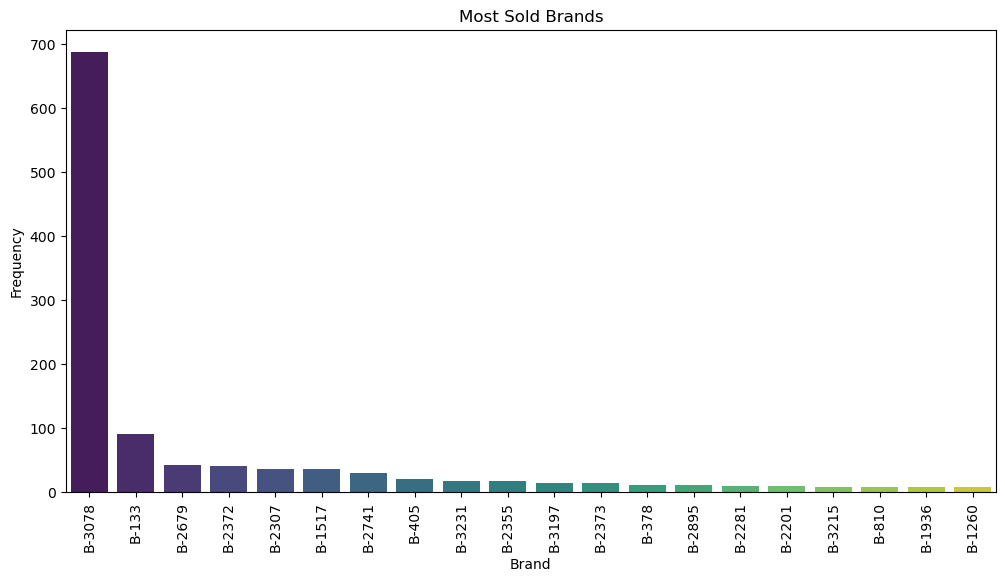

In [ ]:
# Calculate the frequency of each brand
brand_counts = df['Product_Brand'].value_counts().head(20)

# Create a bar plot
bar_plot(brand_counts.index, brand_counts.values, 'Brand', 'Frequency', 'Most Sold Brands')


B-3078 is the most sold brand, followed by B-133.

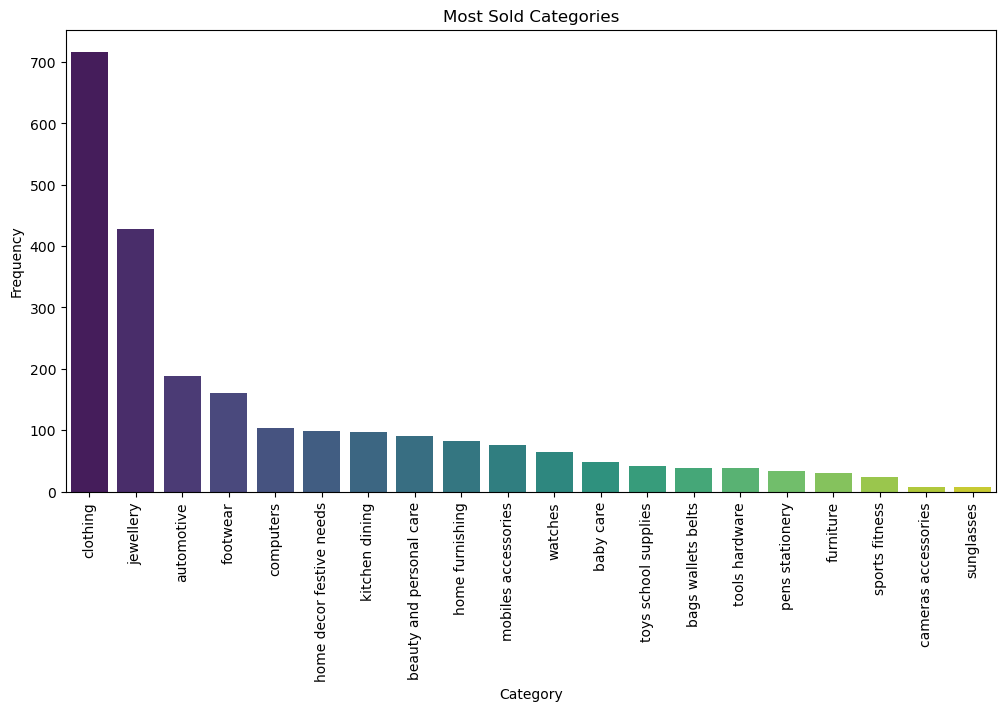

In [ ]:
# Calculate the frequency of each category
cat_counts = df['Item_Category'].value_counts().head(20)

# Create a bar plot
bar_plot(cat_counts.index, cat_counts.values, 'Category', 'Frequency', 'Most Sold Categories')


Clothing is the most sold item category, followed by jewellery.

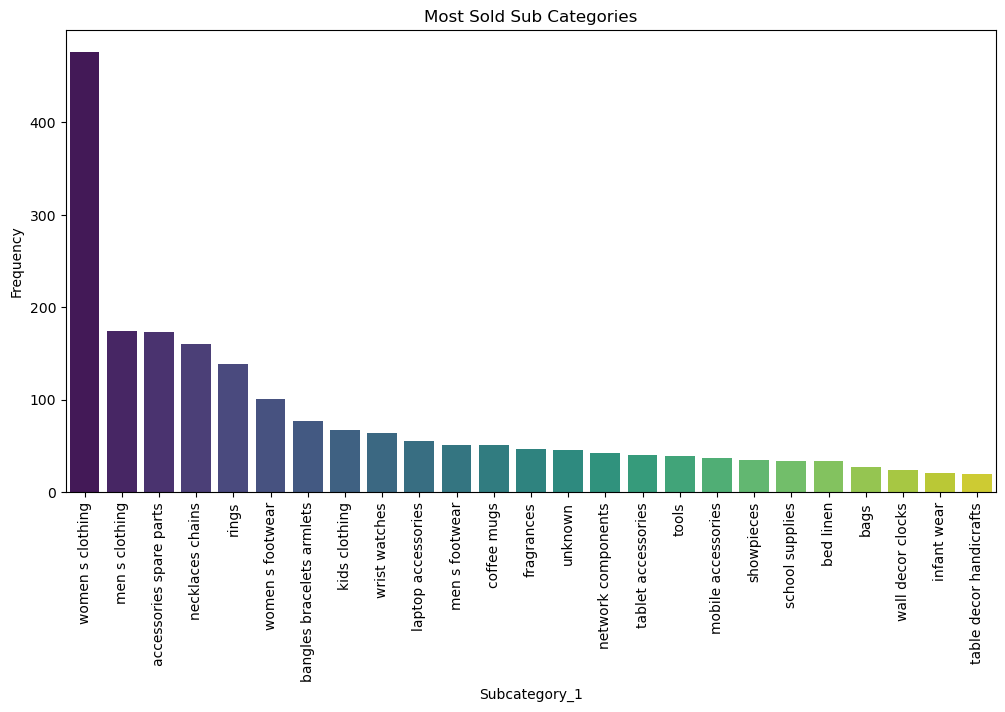

In [ ]:
# Calculate the frequency of each sub category1
sub_cat1_counts = df['Subcategory_1'].value_counts().head(25)

# Create a bar plot
bar_plot(sub_cat1_counts.index, sub_cat1_counts.values, 'Subcategory_1', 'Frequency', 'Most Sold Sub Categories')


Women's Clothing is the most sold sub category, followed by Men's clothing.

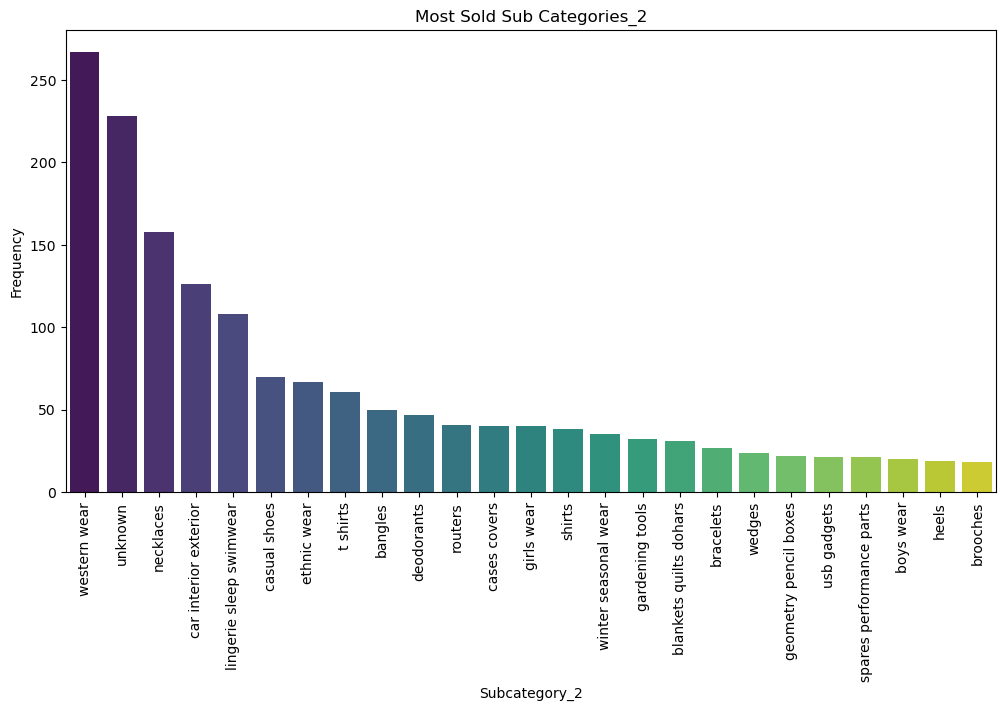

In [ ]:
# Calculate the frequency of each sub category2
sub_cat2_counts = df['Subcategory_2'].value_counts().head(25)

# Create a bar plot
bar_plot(sub_cat2_counts.index, sub_cat2_counts.values, 'Subcategory_2', 'Frequency', 'Most Sold Sub Categories_2')


Western wear are the most sold subcategory_2.

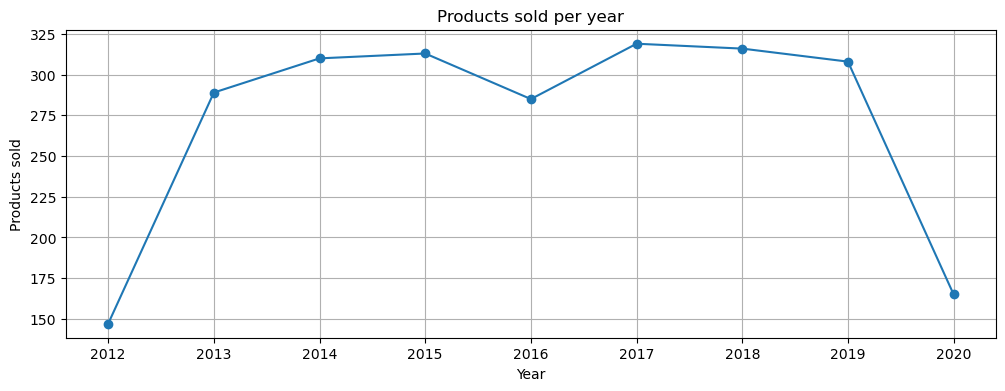

In [ ]:
# Calculate the number of products sold per year (calculating frequency of each year since each row corresponds to a product)
year_counts = df['Year'].value_counts().sort_index()

# Create a line plot
plt.figure(figsize=(12, 4))
plt.plot(year_counts.index, year_counts.values, marker='o', linestyle='-')
plt.xlabel('Year')
plt.ylabel('Products sold')
plt.title('Products sold per year')
plt.grid(True)  # Add grid lines for better readability
plt.show()


E-commerce sales exhibited a rising trend until 2015, experienced a decline in 2016, followed by a resurgence in 2017, but then showed a sustained decrease. Notably, there was a substantial drop from 2019 to 2020, which can likely be attributed to the impact of the COVID-19 pandemic.

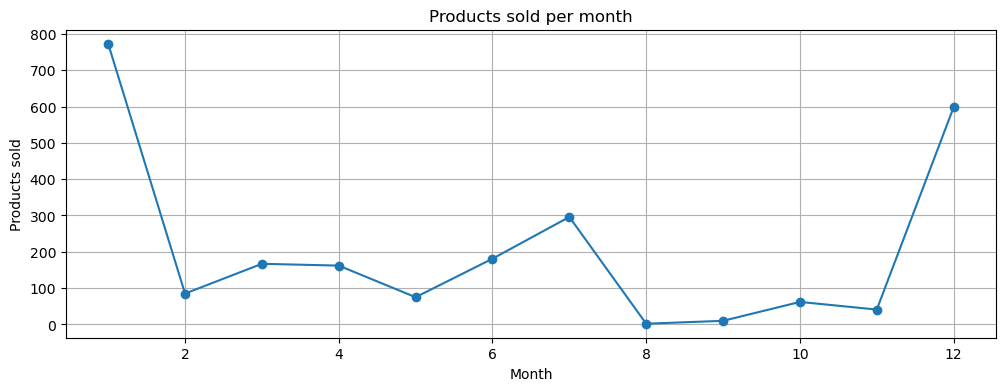

In [ ]:
# # Calculate the number of products sold per month (calculating frequency of each month since each row corresponds to a product)
month_counts = df['Month'].value_counts().sort_index()

# Create a line plot
plt.figure(figsize=(12, 4))
plt.plot(month_counts.index, month_counts.values, marker='o', linestyle='-')
plt.xlabel('Month')
plt.ylabel('Products sold')
plt.title('Products sold per month')
plt.grid(True)  # Add grid lines for better readability
plt.show()


January and December have highest number of products sold.

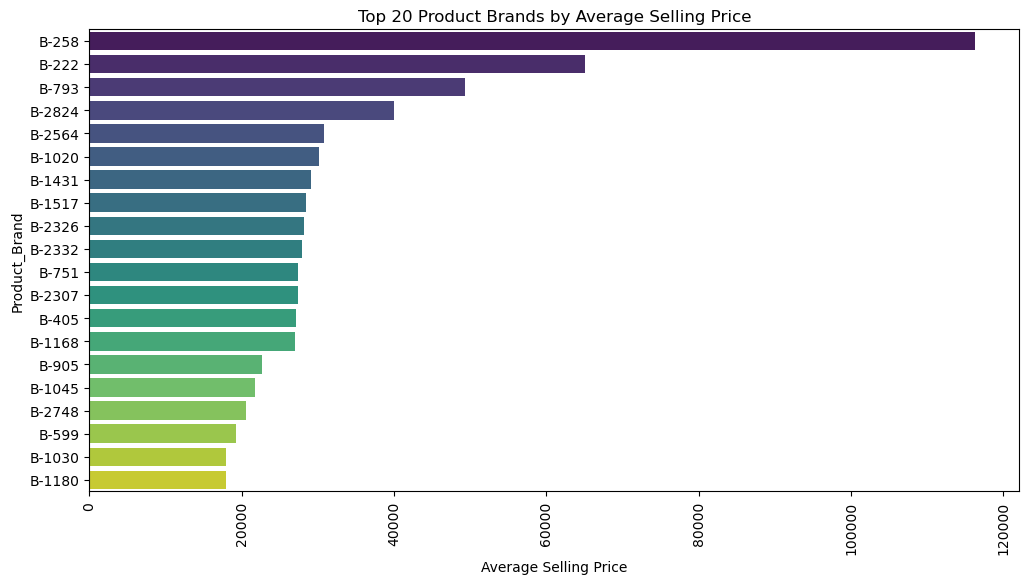

In [ ]:
brand_avg_price = df.groupby('Product_Brand')['Selling_Price'].mean().sort_values(ascending=False)
top_20_brands = brand_avg_price.head(20)

# Create a bar plot
bar_plot(top_20_brands.values, top_20_brands.index, 'Average Selling Price', 'Product_Brand', 
         'Top 20 Product Brands by Average Selling Price')


Products from Brand B-258 have the highest average selling price, followed by B-222.

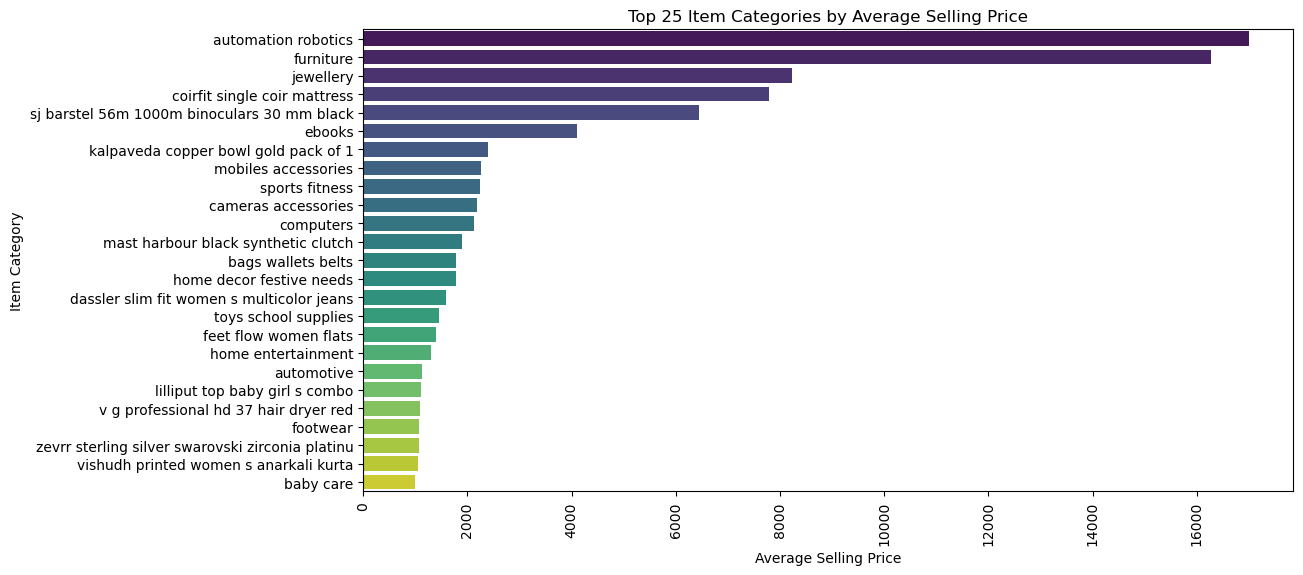

In [ ]:
category_avg_price = df.groupby('Item_Category')['Selling_Price'].mean().sort_values(ascending=False)
top_25_categories = category_avg_price.head(25)
# Create a bar plot
bar_plot(top_25_categories.values, top_25_categories.index, 'Average Selling Price', 'Item Category', 
         'Top 25 Item Categories by Average Selling Price')


Automation Robots have the highest average selling price, followed by furniture.

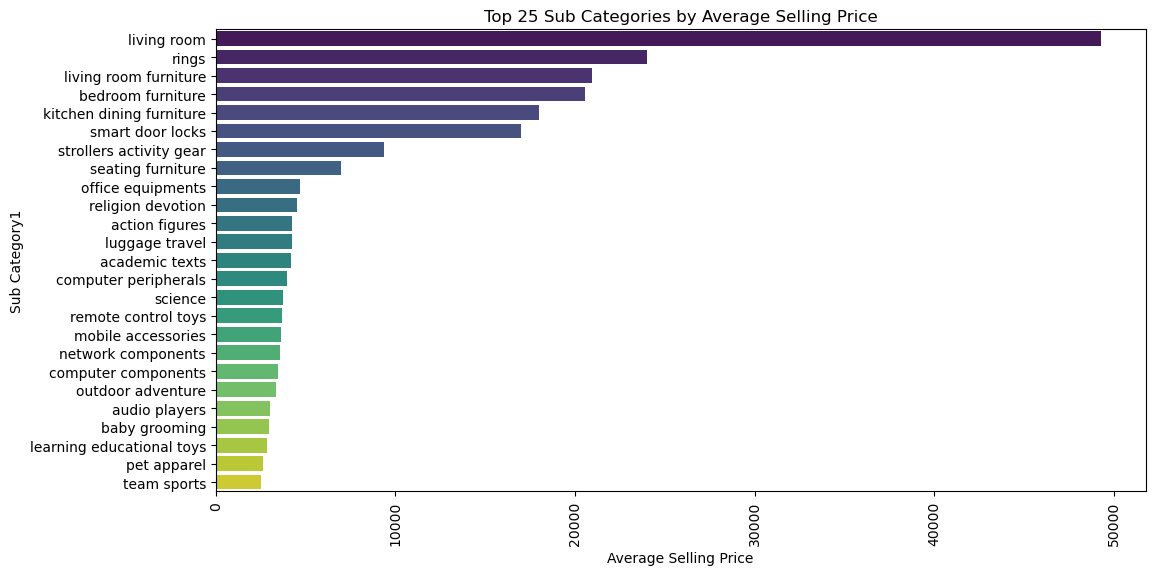

In [ ]:
sub_category_avg_price = df.groupby('Subcategory_1')['Selling_Price'].mean().sort_values(ascending=False)
top_25_sub_categories = sub_category_avg_price.head(25)

# Create a bar plot
bar_plot(top_25_sub_categories.values, top_25_sub_categories.index, 'Average Selling Price', 'Sub Category1', 
         'Top 25 Sub Categories by Average Selling Price')


Products from sub categories Living Room, followed by Rings have the highest average selling prices.

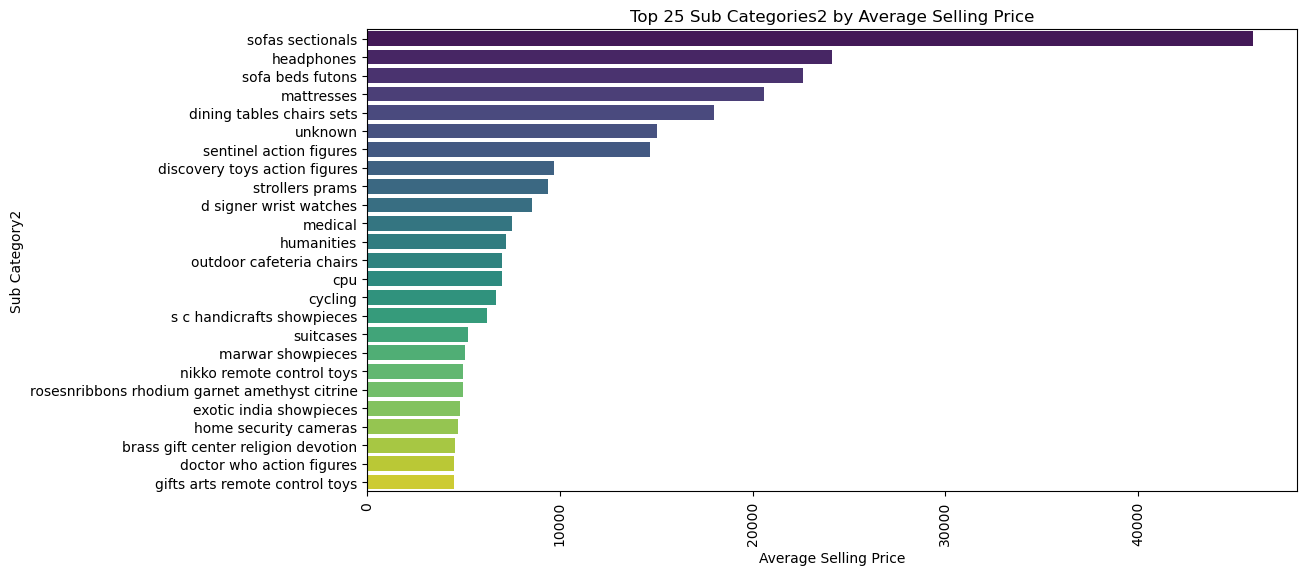

In [ ]:
sub_category2_avg_price = df.groupby('Subcategory_2')['Selling_Price'].mean().sort_values(ascending=False)
top_25_sub_categories2 = sub_category2_avg_price.head(25)

# Create a bar plot
bar_plot(top_25_sub_categories2.values, top_25_sub_categories2.index, 'Average Selling Price', 'Sub Category2', 
         'Top 25 Sub Categories2 by Average Selling Price')


Products from sub categories2 Sofa Sectionals, followed by Headphones have the highest average selling prices.

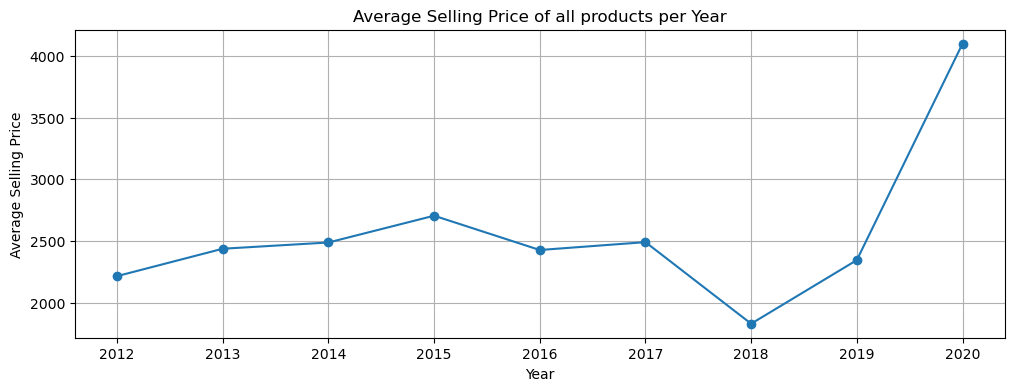

In [ ]:
# Group the data by year and calculate the average selling price of all products for each year
avg_price_per_year = df.groupby('Year')['Selling_Price'].mean()

# Create a line plot
plt.figure(figsize=(12, 4))
plt.plot(avg_price_per_year.index, avg_price_per_year.values, marker='o', linestyle='-')
plt.xlabel('Year')
plt.ylabel('Average Selling Price')
plt.title('Average Selling Price of all products per Year')
plt.grid(True)  # Add grid lines for better readability
plt.show()


There is a significant increase in the average selling price of products in 2020.This increase could be attributed to an increase in demand coupled with a limited supply of products or price inflation influenced by the impact of the COVID-19 pandemic.

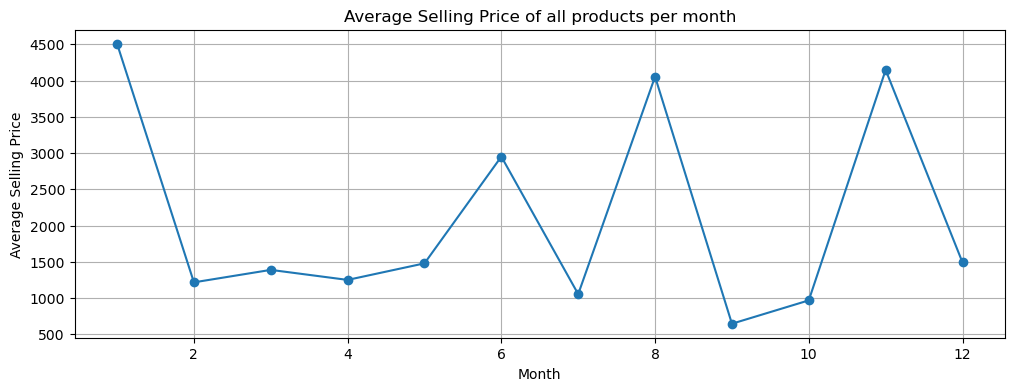

In [ ]:
# Group the data by month and calculate the average selling price of all products for each year
avg_price_per_month = df.groupby('Month')['Selling_Price'].mean()

# Create a line plot
plt.figure(figsize=(12, 4))
plt.plot(avg_price_per_month.index, avg_price_per_month.values, marker='o', linestyle='-')
plt.xlabel('Month')
plt.ylabel('Average Selling Price')
plt.title('Average Selling Price of all products per month')
plt.grid(True)  # Add grid lines for better readability
plt.show()


January, June, August and November have high average selling prices.This could be influenced by seasonal trends or sales and promotions in these months.

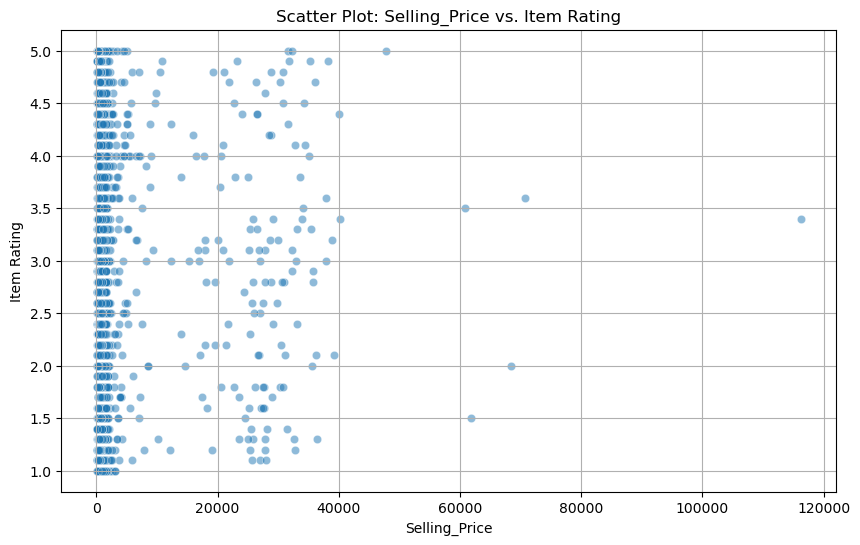

In [ ]:
# Create a scatter plot Selling_Price vs. Item Rating

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Selling_Price', y='Item_Rating', alpha=0.5)
plt.xlabel('Selling_Price')
plt.ylabel('Item Rating')
plt.title('Scatter Plot: Selling_Price vs. Item Rating')
plt.grid(True)
plt.show()


The scatter plot shows that there isn't a significant effect of 'Item Rating' on 'Selling Price.'

Text(0.5, 1.0, 'Histogram')

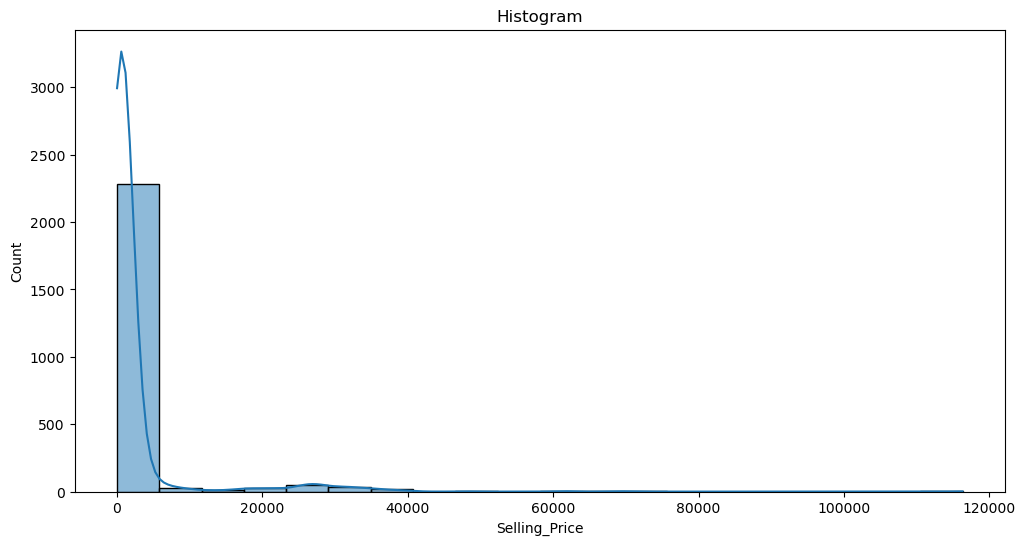

In [ ]:
# Distribution of Selling_Price
plt.figure(figsize=(12, 6))

# Histogram
sns.histplot(df['Selling_Price'],bins = 20,kde = True)
plt.title('Histogram')


Selling_price column is highly skewed to the left.We need to normalise the column.

Normalising Selling_Price
¶

In [ ]:
# Apply log transformation to the 'Selling_Price' column
df['Standardized_Selling_Price'] = df['Selling_Price'].apply(np.log)
df['Standardized_Selling_Price'].head()
df.drop('Selling_Price', axis=1, inplace = True)  # Drop Selling Price column, we use Standardized_Selling_Price here after


Text(0.5, 1.0, 'Standardized Selling_Price Histogram')

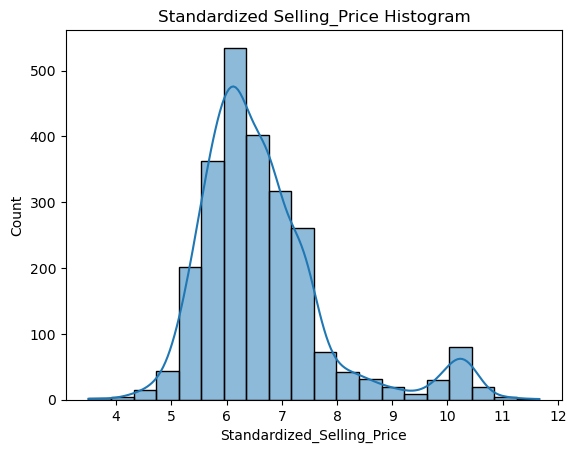

In [ ]:
# Distribution of Normalised Selling_Price
sns.histplot(df['Standardized_Selling_Price'],bins = 20, kde=True)
plt.title('Standardized Selling_Price Histogram')


In [ ]:
# Product_Brand has 1010 unique values.Instead of one hot encoding, extract numeric part from the values 
df['Product_Brand']=df['Product_Brand'].str.extract('(\d+)').astype(int)
df['Product_Brand'] = df['Product_Brand'].astype(int)
df['Product_Brand'].head()  # Check for changes


0     659
1    3078
2    1810
3    3078
4    3078
Name: Product_Brand, dtype: int32

In [ ]:
df.drop(['Product'],axis=1,inplace=True)  # Remove Product column because it won't effect the prediction(since each product has a unique row)


In [ ]:
new_df = df.copy()  #Saving a copy of the dataframe for encoding approach 2.


Approach1:One hot Encoding
¶

In [ ]:
# Function to perform one-hot encoding for the given categorical columns 

def one_hot_encode_top_values(df, column_name, top_values_series):
    for index in top_values_series.index:
        df[f'{column_name}_{index}'] = (df[column_name] == index).astype(int)
    return df

# Pick top 25 elements which have the highest average selling price from the 'Item_Category', 'Subcategory_1', 'Subcategory_2'
    #columns and perform one-hot encoding 
columns_to_encode = ['Item_Category', 'Subcategory_1', 'Subcategory_2']

for column in columns_to_encode:
    top_values_series = top_25_categories if column == 'Item_Category' else \
                        top_25_sub_categories if column == 'Subcategory_1' else \
                        top_25_sub_categories2
    df = one_hot_encode_top_values(df, column, top_values_series)

df.drop(columns=columns_to_encode, inplace=True)  # Drop the categorical columns after one hot encoding is done
df.head()


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
Int64Index: 2452 entries, 0 to 2451
Data columns (total 80 columns):
 #   Column                                                          Non-Null Count  Dtype  
---  ------                                                          --------------  -----  
 0   Product_Brand                                                   2452 non-null   int32  
 1   Item_Rating                                                     2452 non-null   float64
 2   Month                                                           2452 non-null   int64  
 3   Year                                                            2452 non-null   int64  
 4   Standardized_Selling_Price                                      2452 non-null   float64
 5   Item_Category_automation robotics                               2452 non-null   int32  
 6   Item_Category_furniture                                         2452 non-null   int32  
 7   Item_Category_jewellery                            

The DataFrame now contains a total of 80 columns, which include information about the product brand, item rating, month, year, standardized selling price, as well as encoded 25 one hot encoded columns of Item_Category, 25 one hot encoded columns of Subcategory_1 and 25 one hot encoded columns of Subcategory_2).

In [ ]:
# Correlation matrix of all numeric columns
corr_matrix = df.corr()
corr_matrix["Standardized_Selling_Price"].sort_values(ascending=False)


Standardized_Selling_Price            1.000000
Subcategory_1_rings                   0.652799
Subcategory_2_unknown                 0.503307
Item_Category_jewellery               0.237568
Subcategory_2_sofas sectionals        0.204698
                                        ...   
Item_Category_mobiles accessories    -0.038197
Item_Category_toys school supplies   -0.055333
Subcategory_1_mobile accessories     -0.055744
Month                                -0.143571
Product_Brand                        -0.144437
Name: Standardized_Selling_Price, Length: 80, dtype: float64

Data Splitting
¶

In [ ]:
y=df['Standardized_Selling_Price']  # Target
X=df.drop(['Standardized_Selling_Price'],axis=1)  # Features


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42) #Splitting data into train and test datasets
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)


(1961, 79) (1961,)
(491, 79) (491,)


Model Building and Performance
¶

Linear Regression
¶

In [ ]:
# Train using Linear Regression
model = linear_model.LinearRegression()
model.fit(X_train, y_train)
y_hat = model.predict(X_test)


In [ ]:
# Model performance
print('Coefficients:', model.coef_)
print('Intercept:', model.intercept_)
print('Linear Regression Coefficient of determination (R^2): %.3f' % r2_score(y_test, y_hat)) 
print('Linear Regression Mean squared error (MSE): %.3f'% mean_squared_error(y_test, y_hat))
print('Linear Regression Root mean squared error (RMSE) : %.3f'% sqrt(mean_squared_error(y_test, y_hat)))


Coefficients: [-2.73325168e-05  4.35976212e-03 -5.79879702e-04 -4.36721920e-03
  1.62676325e+00  5.03557535e-01 -2.95835166e-01  2.49031101e+00
  2.34925190e+00 -1.03480852e-01  1.30790299e+00  3.78157361e-01
  5.74940419e-01  1.06034554e+00 -1.63579518e-02  1.09595131e+00
  2.97520919e-01  4.39933056e-01  1.54015689e-13 -8.50278934e-01
  7.71539410e-01 -1.49920863e+00  5.10488932e-01  5.58532243e-01
  5.59576203e-01  5.45031138e-01  5.50410521e-01  5.38436849e-01
  2.67146054e-01  1.92539398e+00  3.71372307e+00  4.68958206e-13
 -9.26037025e-13  1.50364531e+00  1.62676325e+00  1.29257282e+00
  1.04809613e+00  1.09136913e+00  8.24944258e-01  2.48666983e-01
  9.02399263e-01 -1.03480852e-01  1.47823489e+00 -3.85913523e-13
  2.32778883e+00 -6.18545764e-01  1.54441221e+00  1.82940025e+00
 -2.12444841e-01  2.70439914e+00  1.46748396e+00  1.55431223e-13
  1.62092999e+00  8.57738715e-01  1.92539398e+00  3.20449380e+00
 -9.43160074e-14  6.61692923e-14  1.50364531e+00  1.74557352e-01
  3.9270313

R^2 = 0.434 suggests that approximately 43% of the variance in the dependent variable(Selling Price) is explained by the independent variables(brand, category, sub categories, month and year). 
On an average, the model's predictions deviate from the actual values by 0.779 units squared.

On an average, the model's predictions deviate from the actual values by 0.883 units in the original scale.

Random Forest Regressor
¶

In [ ]:
# Train using RandomForestRegressor 
forest_reg = RandomForestRegressor()
forest_reg.fit(X_train, y_train)


RandomForestRegressor()

In [ ]:
# Model evaluation
print('Random Forest Regressor Coefficient of determination (R^2): %.3f' % forest_reg.score(X_test, y_test))
y_hat = forest_reg.predict(X_test)
forest_mse = mean_squared_error(y_test, y_hat)
print('Random Forest Regressor Mean squared error (MSE): %.3f' % forest_mse)
forest_rmse = np.sqrt(forest_mse)
print('Random Forest Regressor Root mean squared error (RMSE): %.3f' % forest_rmse)


Random Forest Regressor Coefficient of determination (R^2): 0.576
Random Forest Regressor Mean squared error (MSE): 0.584
Random Forest Regressor Root mean squared error (RMSE): 0.764


Decision Tree Regressor
¶

In [ ]:
# train the model using Decision Tree Regression 
decision_reg = DecisionTreeRegressor()
decision_reg.fit(X_train, y_train)
y_hat = decision_reg.predict(X_test)


In [ ]:
# Model evaluation
print('Decision Tree Regressor Coefficient of determination (R^2): %.3f' % r2_score(y_test, y_hat))
decision_mse = mean_squared_error(y_test, y_hat)
print('Decision Tree Regressor Mean squared error (MSE): %.3f' % decision_mse)
decision_rmse = np.sqrt(decision_mse)
print('Decision Tree  Regressor Root mean squared error (RMSE): %.3f' % decision_rmse)


Decision Tree Regressor Coefficient of determination (R^2): 0.308
Decision Tree Regressor Mean squared error (MSE): 0.952
Decision Tree  Regressor Root mean squared error (RMSE): 0.976


XGBoost Regressor
¶

In [ ]:
# Train the XGBoost Regression model
xgb_model = xgb.XGBRegressor()
xgb_model.fit(X_train, y_train)
y_hat = xgb_model.predict(X_test)


In [ ]:
# Model evaluation
print(' XGBoost Regressor Coefficient of determination (R^2): %.3f' % r2_score(y_test, y_hat))
xgb_model_mse = mean_squared_error(y_test, y_hat)
print(' XGBoost Regressor Mean squared error (MSE): %.3f' % xgb_model_mse)
xgb_model_rmse = np.sqrt(xgb_model_mse)
print(' XGBoost Regressor Root mean squared error (RMSE): %.3f' % xgb_model_rmse)


 XGBoost Regressor Coefficient of determination (R^2): 0.519
 XGBoost Regressor Mean squared error (MSE): 0.662
 XGBoost Regressor Root mean squared error (RMSE): 0.814


The best performing models are Random Forest Regressor(R^2 = 0.576) and XGBoost Regressor(R^2 = 0.519).

Improving performance
¶

Grid Search CV for Random forest
¶

In [ ]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 3, 4, 5],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

forest_reg = RandomForestRegressor()

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=forest_reg, param_grid=param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)

# Fit the grid search and get the best hyperparameters
grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)

# Get the best model
best_model = grid_search.best_estimator_
y_hat = best_model.predict(X_test)


Best Hyperparameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 300}


In [ ]:
# Model evaluation
print(' Improved Random Forest Regressor Coefficient of determination (R^2): %.3f' % r2_score(y_test, y_hat))
best_model_mse = mean_squared_error(y_test, y_hat)
print(' Improved Random Forest Regressor Mean squared error (MSE): %.3f' % best_model_mse)
best_model_rmse = np.sqrt(best_model_mse)
print(' Improved Random Forest Regressor Root mean squared error (RMSE): %.3f' % best_model_rmse)


 Improved Random Forest Regressor Coefficient of determination (R^2): 0.600
 Improved Random Forest Regressor Mean squared error (MSE): 0.551
 Improved Random Forest Regressor Root mean squared error (RMSE): 0.742


After Grid Search on Forest Regressor, R^2 score increased from 0.576 to 0.600 .

Grid Search CV for XGBoost
¶

In [ ]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2],
}
xgb_model = xgb.XGBRegressor()

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=xgb_model, param_grid=param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)

# Fit the grid search and get the best hyperparameters
grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)

# Get the best model
best_model = grid_search.best_estimator_
y_hat = best_model.predict(X_test)


Best Hyperparameters: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 200}


In [ ]:
# Model evaluation
print(' Improved XGBoost Regressor Coefficient of determination (R^2): %.3f' % r2_score(y_test, y_hat))
best_model_mse = mean_squared_error(y_test, y_hat)
print(' Improved XGBoost Regressor Mean squared error (MSE): %.3f' % best_model_mse)
best_model_rmse = np.sqrt(best_model_mse)
print(' Improved XGBoost Regressor Root mean squared error (RMSE): %.3f' % best_model_rmse)


 Improved XGBoost Regressor Coefficient of determination (R^2): 0.532
 Improved XGBoost Regressor Mean squared error (MSE): 0.645
 Improved XGBoost Regressor Root mean squared error (RMSE): 0.803


After Grid Search on Forest Regressor, R^2 score increased from 0.519 to 0.532 .

Best fitted model achieved using Best hyperparameters using Grid search CV Random Forest Regressor with R^2 score = 0.6 and RMSE = 0.742 .
¶

Approach2: Using Target Encoding
¶

In [ ]:
# Target encoding all the 3 categorical columns.That is, the average value of the target variable in each level group of 
    #the categorical variable is aggregated and replaced with that value.
categorical_columns = ['Item_Category', 'Subcategory_1', 'Subcategory_2']

new_df[categorical_columns] = TargetEncoder().fit_transform(new_df[categorical_columns], new_df['Standardized_Selling_Price'])
print(new_df.head())

df = new_df.copy()  #Copying the data back to df  


   Product_Brand  Item_Category  Subcategory_1  Subcategory_2  Item_Rating  \
0            659       6.848870       6.682322       6.703373          4.3   
1           3078       6.353247       6.260392       6.347690          3.1   
2           1810       6.880514       6.855501       6.673264          3.5   
3           3078       6.055726       6.674058       6.660863          4.0   
4           3078       6.353247       6.533462       6.195622          4.3   

   Month  Year  Standardized_Selling_Price  
0      2  2017                    5.673323  
1      7  2015                    6.799056  
2      1  2019                    6.674561  
3     12  2014                    6.729824  
4     12  2013                    6.152733  


<Axes: >

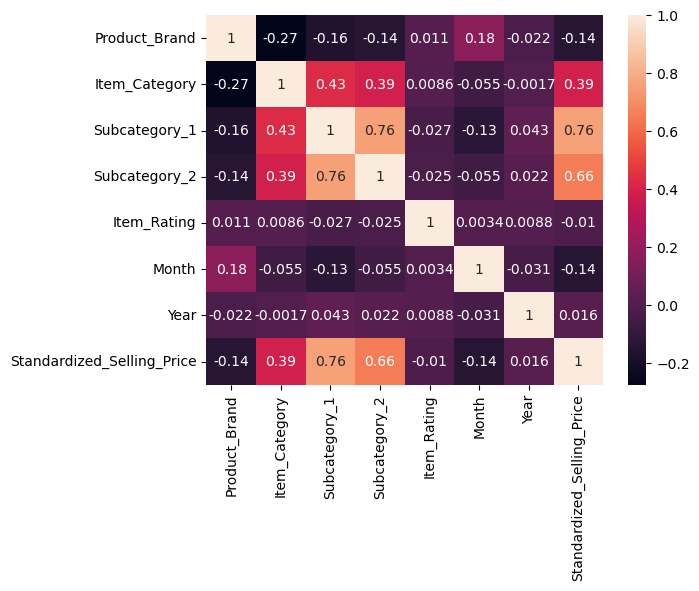

In [ ]:
# Correlation matrix of all numeric columns
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot = True)


The plot shows that Selling_Price is highly positively related to Subcategory_1, followed by Subcategory_2 and Item_category.Month, Year, Product_Brand and Item_Rating have very weak relation with Selling_price.

Data Splitting
¶

In [ ]:
y=df['Standardized_Selling_Price']  # Target
X=df.drop(['Standardized_Selling_Price'],axis=1)  # Features


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)


(1961, 7) (1961,)
(491, 7) (491,)


Model Building and Performance
¶

Linear Regression
¶

In [ ]:
# Train using Linear Regression
model = linear_model.LinearRegression()
model.fit(X_train, y_train)
y_hat = model.predict(X_test)


In [ ]:
# Model performance
print('Coefficients:', model.coef_)
print('Intercept:', model.intercept_)
print('Linear Regression Coefficient of determination (R^2): %.3f' % r2_score(y_test, y_hat))
print('Linear Regression Mean squared error (MSE): %.3f'% mean_squared_error(y_test, y_hat))
print('Linear Regression Root mean squared error (RMSE) : %.3f'% sqrt(mean_squared_error(y_test, y_hat)))


Coefficients: [-4.15357496e-06  1.23552389e-01  8.60760969e-01  2.78048428e-01
  2.08047122e-02 -1.54621194e-02 -7.67785536e-03]
Intercept: 13.746811457442366
Linear Regression Coefficient of determination (R^2): 0.541
Linear Regression Mean squared error (MSE): 0.632
Linear Regression Root mean squared error (RMSE) : 0.795


Random Forest Regressor
¶

In [ ]:
# Train using RandomForestRegressor 
forest_reg = RandomForestRegressor()
forest_reg.fit(X_train, y_train)


RandomForestRegressor()

In [ ]:
# Model evaluation
print('Random Forest Regressor Coefficient of determination (R^2): %.3f' % forest_reg.score(X_test, y_test))
y_hat = forest_reg.predict(X_test)
forest_mse = mean_squared_error(y_test, y_hat)
print('Random Forest Regressor Mean squared error (MSE): %.3f' % forest_mse)
forest_rmse = np.sqrt(forest_mse)
print('Random Forest Regressor Root mean squared error (RMSE): %.3f' % forest_rmse)


Random Forest Regressor Coefficient of determination (R^2): 0.724
Random Forest Regressor Mean squared error (MSE): 0.380
Random Forest Regressor Root mean squared error (RMSE): 0.616


Decision Tree Regressor
¶

In [ ]:
# train the model using Decision Tree Regression 
decision_reg = DecisionTreeRegressor()
decision_reg.fit(X_train, y_train)
y_hat = decision_reg.predict(X_test)


In [ ]:
# Model evaluation
print(' XGBoost Regressor Coefficient of determination (R^2): %.3f' % r2_score(y_test, y_hat))
xgb_model_mse = mean_squared_error(y_test, y_hat)
print(' XGBoost Regressor Mean squared error (MSE): %.3f' % xgb_model_mse)
xgb_model_rmse = np.sqrt(xgb_model_mse)
print(' XGBoost Regressor Root mean squared error (RMSE): %.3f' % xgb_model_rmse)


 XGBoost Regressor Coefficient of determination (R^2): 0.501
 XGBoost Regressor Mean squared error (MSE): 0.686
 XGBoost Regressor Root mean squared error (RMSE): 0.829


XGBoost Regressor
¶

In [ ]:
# Train the XGBoost Regression model
xgb_model = xgb.XGBRegressor()
xgb_model.fit(X_train, y_train)
y_hat = xgb_model.predict(X_test)


In [ ]:
# Model evaluation
print(' XGBoost Regressor Coefficient of determination (R^2): %.3f' % r2_score(y_test, y_hat))
xgb_model_mse = mean_squared_error(y_test, y_hat)
print(' XGBoost Regressor Mean squared error (MSE): %.3f' % xgb_model_mse)
xgb_model_rmse = np.sqrt(xgb_model_mse)
print(' XGBoost Regressor Root mean squared error (RMSE): %.3f' % xgb_model_rmse)


 XGBoost Regressor Coefficient of determination (R^2): 0.671
 XGBoost Regressor Mean squared error (MSE): 0.453
 XGBoost Regressor Root mean squared error (RMSE): 0.673


Improving performance
¶

Grid Search CV for Random forest
¶

In [ ]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 3, 4, 5],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
forest_reg = RandomForestRegressor()

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=forest_reg, param_grid=param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)

# Fit the grid search to data and get the best hyperparameters
grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)

# Get the best model
best_model = grid_search.best_estimator_
y_hat = best_model.predict(X_test)


Best Hyperparameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 300}


In [ ]:
# Model evaluation
print(' Improved Random Forest Regressor Coefficient of determination (R^2): %.3f' % r2_score(y_test, y_hat))
best_model_mse = mean_squared_error(y_test, y_hat)
print(' Improved Random Forest Regressor Mean squared error (MSE): %.3f' % best_model_mse)
best_model_rmse = np.sqrt(best_model_mse)
print(' Improved Random Forest Regressor Root mean squared error (RMSE): %.3f' % best_model_rmse)


 Improved Random Forest Regressor Coefficient of determination (R^2): 0.723
 Improved Random Forest Regressor Mean squared error (MSE): 0.382
 Improved Random Forest Regressor Root mean squared error (RMSE): 0.618


After Grid Search on Forest Regressor in this approach 2, R^2 score is 0.723 .

Grid Search CV for XGBoost
¶

In [ ]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2],
}
xgb_model = xgb.XGBRegressor()

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=xgb_model, param_grid=param_grid, cv=5, scoring='neg_mean_squared_error')

# Fit the grid search to data and get the best hyperparameters
grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)

# Get the best model
best_model = grid_search.best_estimator_
y_hat = best_model.predict(X_test)


Best Hyperparameters: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 100}


In [ ]:
# Model evaluation
print(' Improved XGBoost Regressor Coefficient of determination (R^2): %.3f' % r2_score(y_test, y_hat))
best_model_mse = mean_squared_error(y_test, y_hat)
print(' Improved XGBoost Regressor Mean squared error (MSE): %.3f' % best_model_mse)
best_model_rmse = np.sqrt(best_model_mse)
print(' Improved XGBoost Regressor Root mean squared error (RMSE): %.3f' % best_model_rmse)


 Improved XGBoost Regressor Coefficient of determination (R^2): 0.712
 Improved XGBoost Regressor Mean squared error (MSE): 0.396
 Improved XGBoost Regressor Root mean squared error (RMSE): 0.630


After Grid Search on XGBoost Regressor in this approach 2, R^2 score increased from 0.671 to 0.712 .

Best fitted model achieved using Best hyperparameters using Grid search CV Random Forest Regressor with R^2 score = 0.723 and RMSE = 0.618 .
¶

Importance of Features
¶

In [ ]:
# Create a Random Forest Regressor
forest_reg = RandomForestRegressor(n_estimators=100) 

# Fit the model to the data
forest_reg.fit(X_train, y_train)

# Get feature importances
feature_importances = forest_reg.feature_importances_
feature_names = df.columns
importances_with_names = list(zip(feature_names, feature_importances))
importances_with_names.sort(key=lambda x: x[1], reverse=True)

# Print the feature importances
for feature_name, importance in importances_with_names:
    print(f"{feature_name}: {importance}")


Subcategory_1: 0.513116341804972
Subcategory_2: 0.20936808867654264
Product_Brand: 0.07510728766720849
Item_Category: 0.07485555163581602
Item_Rating: 0.05350597652122602
Month: 0.041287855496927435
Year: 0.032758898197307346


Subcategory_1 is the most influential feature in the model.